In [12]:
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import loadmat
from natsort import natsorted
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

In [ ]:
IMAGE_DIR = Path(r"D:\data-distance-coding-project\raw-data\260219_SAM041_goggles_left")
STIMDATA_PATH = IMAGE_DIR / "stimulus" / "260219_SAM041_goggles_left.mat"
OUTPUT_DIR = IMAGE_DIR / "output"
OUTPUT_DIR.mkdir(exist_ok=True)
FS = 10.0  # frame rate (Hz)

# ── Options ───────────────────────────────────────────────────────────
F0_METHOD        = "median"  # "median" or "mean"
BASELINE_MODE    = "local"   # "local" (per-trial F0) or "global" (session-wide F0)
POSITIONS_OVERRIDE = None    # e.g. np.array([0, 20, 40, 60, 80, 100, 120, 140])
                             # set to None to use positions from the stimulus file

STIM_SOURCE = "mat"          # "mat" (load from .mat file) or "csv" (reconstruct from CSVs)
CSV_DIR     = Path.cwd() / "stim-generation"  # folder with positions.csv & position_order.csv
ON_TIME_CSV  = 2.0           # seconds — used only when STIM_SOURCE = "csv"
OFF_TIME_CSV = 4.0           # seconds — used only when STIM_SOURCE = "csv"

npz_path = OUTPUT_DIR / f"preprocessing_{F0_METHOD}_{BASELINE_MODE}.npz"

## Discover and inspect frames

In [24]:
frame_paths = natsorted(IMAGE_DIR.glob("*.tif"))
n_frames = len(frame_paths)
print(f"Found {n_frames} frames")

sample = tifffile.imread(str(frame_paths[0]))
print(f"Frame shape: {sample.shape}, dtype: {sample.dtype}")
print(f"Pixel range: [{sample.min()}, {sample.max()}]")

Found 4800 frames
Frame shape: (1272, 2030), dtype: uint16
Pixel range: [360, 13693]


## Load stimulus data

In [ ]:
if STIM_SOURCE == "mat":
    raw = loadmat(str(STIMDATA_PATH), squeeze_me=True)
    s = raw["left_stim"]
    stimdata = {name: s[name].item() for name in s.dtype.names}
    stimdata["on_time"]  = float(stimdata["on_time"])
    stimdata["off_time"] = float(stimdata["off_time"])
    stimdata["repeats"]  = int(stimdata["repeats"])
    stimdata["stim_size"] = int(stimdata["stim_size"])
    print(f"Expected duration: {stimdata['stim_end'][-1, -1]:.1f}s, actual frames: {n_frames / FS:.1f}s")

else:  # csv
    positions      = np.loadtxt(str(CSV_DIR / "positions.csv"), delimiter=",")
    position_order = np.loadtxt(str(CSV_DIR / "position_order.csv"), delimiter=",", dtype=int)
    n_repeats = position_order.shape[0]
    n_pos     = len(positions)
    stim_on   = np.array([
        (rep * n_pos + np.arange(n_pos)) * (ON_TIME_CSV + OFF_TIME_CSV) + OFF_TIME_CSV
        for rep in range(n_repeats)
    ])
    stimdata = {
        "positions":      positions,
        "repeats":        n_repeats,
        "on_time":        ON_TIME_CSV,
        "off_time":       OFF_TIME_CSV,
        "stim_on":        stim_on,
        "position_order": position_order,
        "stim_size":      None,
    }
    print(f"Loaded from CSV — {n_repeats} repeats, {n_pos} positions")

if POSITIONS_OVERRIDE is not None:
    stimdata["positions"] = np.asarray(POSITIONS_OVERRIDE)
    print(f"Positions overridden to: {stimdata['positions']}")

print(f"Positions: {stimdata['positions']}")
print(f"Repeats: {stimdata['repeats']}, on_time: {stimdata['on_time']}s, off_time: {stimdata['off_time']}s")
print(f"stim_on shape: {np.atleast_2d(stimdata['stim_on']).shape}")
print(f"position_order shape: {np.atleast_2d(stimdata['position_order']).shape}")

## Compute frame means and global baseline image

In [ ]:
BLOCK_SIZE = 50
n_blocks = (n_frames + BLOCK_SIZE - 1) // BLOCK_SIZE

def _read_tif(p):
    return tifffile.imread(str(p)).astype(np.float32)

def _read_block(start, end):
    paths = frame_paths[start:end]
    with ThreadPoolExecutor() as pool:
        frames = list(pool.map(_read_tif, paths))
    return np.stack(frames, axis=-1)  # (H, W, count)

if npz_path.exists():
    print(f"Loading cached results from {npz_path}")
    data = np.load(npz_path, allow_pickle=True)
    f0 = data["f0"]
    frame_means = data["frame_means"]
    position_responses = data["position_responses"]
    print("Loaded f0, frame_means, position_responses")
else:
    # Compute per-frame spatial means (for photobleaching check)
    frame_means = np.empty(n_frames, dtype=np.float64)
    for b in tqdm(range(n_blocks), desc="Computing frame means"):
        start = b * BLOCK_SIZE
        end = min(start + BLOCK_SIZE, n_frames)
        block = _read_block(start, end)
        frame_means[start:end] = block.mean(axis=(0, 1))

    # Global F0: baseline frames across all trials
    baseline_dur = 2.0  # seconds
    baseline_frames = int(round(baseline_dur * FS))  # 20 frames
    blank_chunks = []
    for rep in range(stimdata["repeats"]):
        for trial in range(stimdata["stim_on"].shape[1]):
            stim_start = int(round(stimdata["stim_on"][rep, trial] * FS))
            bl_start = max(stim_start - baseline_frames, 0)
            if bl_start < stim_start:
                blank_chunks.append(_read_block(bl_start, stim_start))  # (H, W, ~20)

    all_blank = np.concatenate(blank_chunks, axis=-1)  # (H, W, total_blank_frames)
    if F0_METHOD == "median":
        f0 = np.median(all_blank, axis=-1).astype(np.float32)
    else:
        f0 = all_blank.mean(axis=-1).astype(np.float32)
    del all_blank, blank_chunks
    print(f"F0 shape: {f0.shape} ({F0_METHOD} of last {baseline_dur}s of each blank)")

## Visualize baseline and photobleaching

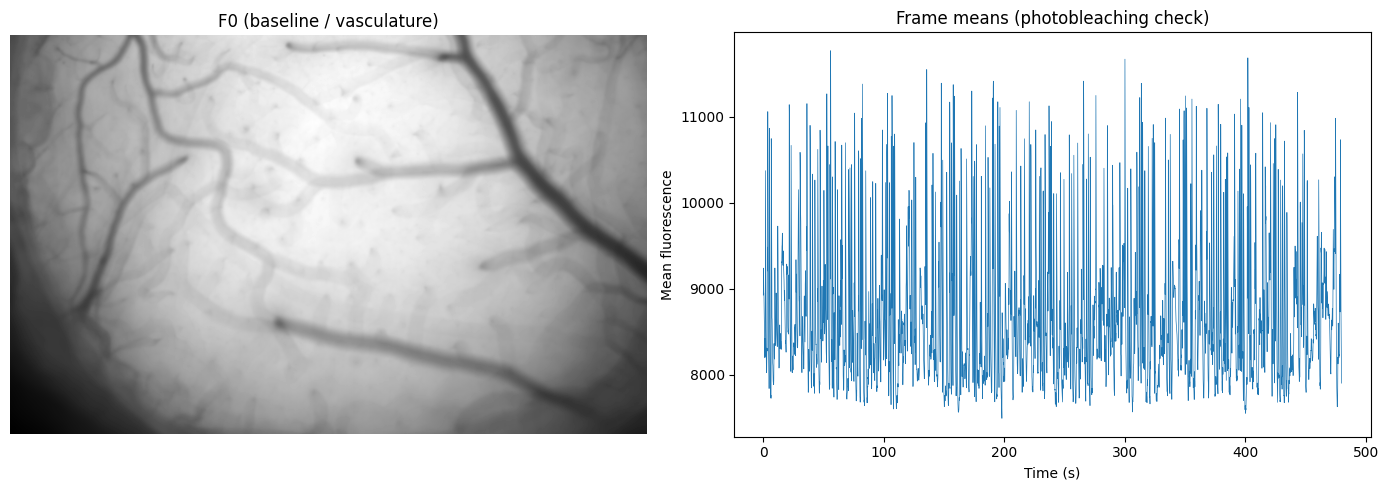

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(f0, cmap="gray")
axes[0].set_title("F0 (baseline / vasculature)")
axes[0].axis("off")

axes[1].plot(np.arange(n_frames) / FS, frame_means, linewidth=0.5)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Mean fluorescence")
axes[1].set_title("Frame means (photobleaching check)")

plt.tight_layout()
plt.show()

## Extract per-position responses (trial-local baseline)

In [ ]:
if not npz_path.exists():
    positions = stimdata["positions"]
    n_positions = len(positions)
    on_frames = int(round(stimdata["on_time"] * FS))
    baseline_frames = int(round(baseline_dur * FS))
    n_repeats = stimdata["repeats"]

    print(f"on_frames: {on_frames}, baseline_frames: {baseline_frames}")
    print(f"Positions: {positions}, n_repeats: {n_repeats}")
    print(f"Baseline mode: {BASELINE_MODE}")

    response_accum = np.zeros((n_positions, f0.shape[0], f0.shape[1], on_frames), dtype=np.float64)
    response_count = np.zeros(n_positions, dtype=int)
    f0_3d = f0[:, :, np.newaxis]

    for rep in tqdm(range(n_repeats), desc="Extracting responses"):
        for trial in range(stimdata["stim_on"].shape[1]):
            stim_start_frame = int(round(stimdata["stim_on"][rep, trial] * FS))
            stim_end_frame = stim_start_frame + on_frames

            if stim_end_frame > n_frames:
                continue

            stim_block = _read_block(stim_start_frame, stim_end_frame)  # (H, W, on_frames)

            if BASELINE_MODE == "local":
                bl_start = max(stim_start_frame - baseline_frames, 0)
                blank_block = _read_block(bl_start, stim_start_frame)  # (H, W, ~20)
                trial_f0 = blank_block.mean(axis=-1, keepdims=True)    # (H, W, 1)
            else:
                trial_f0 = f0_3d  # (H, W, 1)

            dff = (stim_block - trial_f0) / trial_f0 * 100

            pos_idx = stimdata["position_order"][rep, trial] - 1  # MATLAB 1-indexed
            response_accum[pos_idx] += dff
            response_count[pos_idx] += 1

    position_responses = response_accum / response_count[:, None, None, None]
    print(f"position_responses shape: {position_responses.shape}")
    print(f"Trials per position: {response_count}")

## Visualize mean response per position

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_37908\3035535463.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


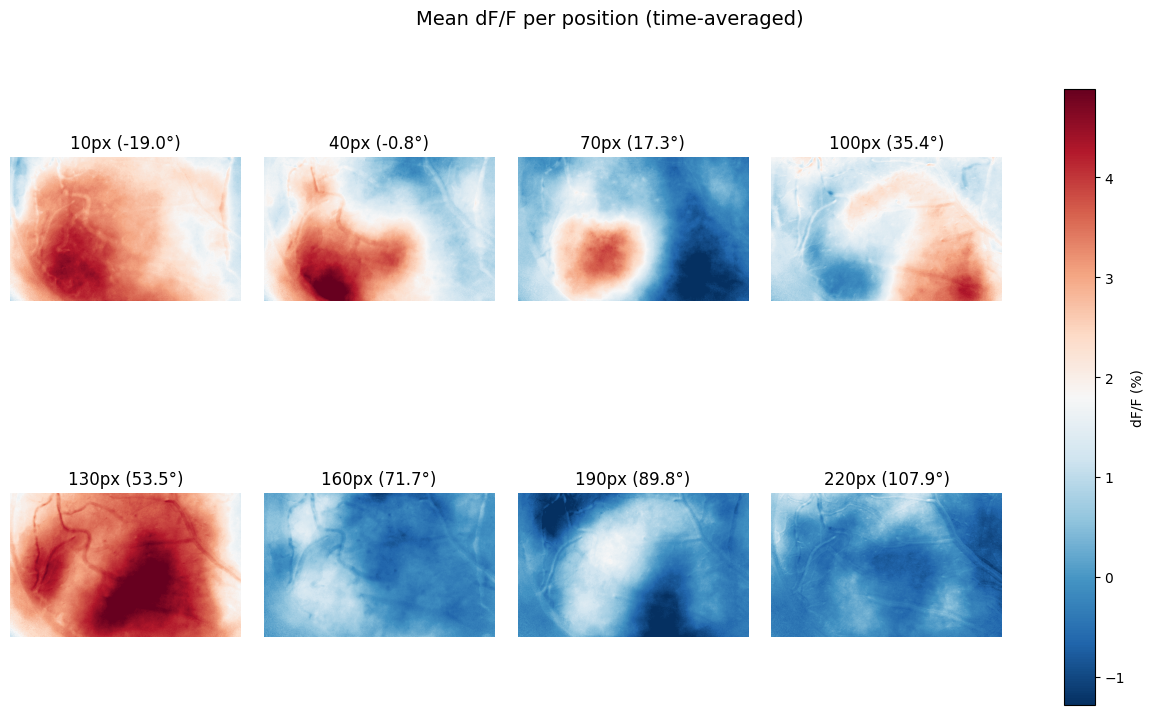

In [29]:

positions = stimdata["positions"]
n_positions = len(positions)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), gridspec_kw={"wspace": 0.1, "hspace": 0.2})
axes = axes.ravel()

vmin = np.percentile(position_responses.mean(axis=-1), 1)
vmax = np.percentile(position_responses.mean(axis=-1), 99)

pos_deg = -25 + (positions / 240) * (120 - (-25))

for i in range(n_positions):
    mean_resp = position_responses[i].mean(axis=-1)
    im = axes[i].imshow(mean_resp, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    axes[i].set_title(f"{positions[i]}px ({pos_deg[i]:.1f}°)")
    axes[i].axis("off")

fig.colorbar(im, ax=axes, label="dF/F (%)")
fig.suptitle("Mean dF/F per position (time-averaged)", fontsize=14)
plt.tight_layout()
plt.show()

## Save preprocessing results

In [ ]:
if not npz_path.exists():
    save_dict = dict(
        f0=f0,
        frame_means=frame_means,
        position_responses=position_responses,
        positions=stimdata["positions"],
        position_order=stimdata["position_order"],
        on_time=stimdata["on_time"],
        off_time=stimdata["off_time"],
        repeats=stimdata["repeats"],
    )
    if stimdata["stim_size"] is not None:
        save_dict["stim_size"] = stimdata["stim_size"]
    np.savez(npz_path, **save_dict)
    print(f"Saved preprocessing results to {npz_path}")
else:
    print(f"Results already cached at {npz_path}")